In [13]:

import numpy as np
import pandas as pd

np.random.seed(23)

# Generate samples for Class 1
mu_vec1 = np.array([0, 0, 0])
cov_mat1 = np.array([
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1]
])

class1_sample = np.random.multivariate_normal(
    mu_vec1, cov_mat1, 20
)

df = pd.DataFrame(
    class1_sample,
    columns=['feature1', 'feature2', 'feature3']
)

df['target'] = 1

# Generate samples for Class 2
mu_vec2 = np.array([1, 1, 1])
cov_mat2 = np.array([
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1]
])

class2_sample = np.random.multivariate_normal(
    mu_vec2, cov_mat2, 20
)

df1 = pd.DataFrame(
    class2_sample,
    columns=['feature1', 'feature2', 'feature3']
)

df1['target'] = 0

# Combine both DataFrames
df = pd.concat([df, df1], ignore_index=True)

# Shuffle all 40 rows
df = df.sample(frac=1, random_state=23).reset_index(drop=True)

# Display the result
print(df)
print("\nShape:", df.shape)
print("\nClass distribution:")
print(df['target'].value_counts())


    feature1  feature2  feature3  target
0  -0.331617 -1.632386  0.619114       1
1   1.010229  1.437830  2.327788       0
2   0.241106 -0.952510 -0.136267       1
3   1.676860  4.187503 -0.080565       0
4   2.823378 -0.332863  2.637391       0
5  -0.723253  1.461259 -0.085367       0
6   1.415320  0.457711  0.728876       1
7   1.772258 -0.347459  0.670140       1
8   0.420623  0.411620 -0.071324       1
9   1.437892  1.099723  1.065406       0
10  0.204637 -0.011535  3.150780       0
11  1.250737  0.186384  1.703624       0
12 -1.389866  0.666726  1.343517       0
13  0.322272  0.060343 -1.043450       1
14  1.045371  0.538162  0.812119       1
15  0.748855  2.593111  1.170818       0
16  0.948634  0.701672 -1.051082       1
17 -0.045438  1.040886 -0.094035       1
18 -1.027861  1.131416  2.603234       0
19 -0.420844 -0.551989 -0.121098       1
20  1.425140  1.441152  0.182561       0
21  0.666988  0.025813 -0.777619       1
22 -1.009942  0.441736  1.128877       1
23  0.731858  0.

In [14]:
df.head()

,feature1,feature2,feature3,target
0,-0.331617,-1.632386,0.619114,1
1,1.010229,1.437830,2.327788,0
2,0.241106,-0.952510,-0.136267,1
3,1.676860,4.187503,-0.080565,0
4,2.823378,-0.332863,2.637391,0


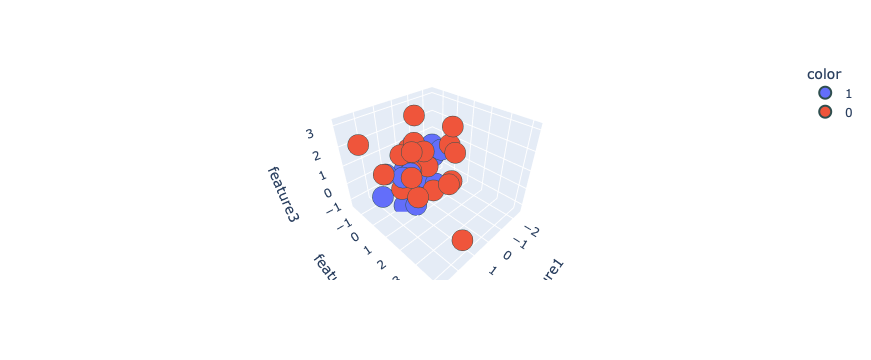

In [15]:

import plotly.express as px
#y_train_trf = y_train.astype(str)
fig = px.scatter_3d(df, x=df['feature1'], y=df['feature2'], z=df['feature3'],
              color=df['target'].astype('str'))
fig.update_traces(marker=dict(size=12,
                              line=dict(width=2,
                                        color='DarkSlateGrey')),
                  selector=dict(mode='markers'))

fig.show()

In [16]:

# Step 1 - Apply standard scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

df.iloc[:,0:3] = scaler.fit_transform(df.iloc[:,0:3])

In [17]:

# Step 2 - Find Covariance Matrix
covariance_matrix = np.cov([df.iloc[:,0],df.iloc[:,1],df.iloc[:,2]])
print('Covariance Matrix:\n', covariance_matrix)

Covariance Matrix:
 [[1.02564103 0.20478114 0.080118  ]
 [0.20478114 1.02564103 0.19838882]
 [0.080118   0.19838882 1.02564103]]


In [18]:
# Step 3 - Finding EV and EVs
eigen_values, eigen_vectors = np.linalg.eig(covariance_matrix)

In [19]:

eigen_values

array([1.3536065 , 0.94557084, 0.77774573])

In [20]:

eigen_vectors

array([[-0.53875915, -0.69363291,  0.47813384],
       [-0.65608325, -0.01057596, -0.75461442],
       [-0.52848211,  0.72025103,  0.44938304]])

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


AttributeError: 'Arrow3D' object has no attribute 'do_3d_projection'

<Figure size 700x700 with 1 Axes>

In [10]:
pc = eigen_vectors[0:2]
pc

array([[-0.65172443,  0.74834128,  0.12345283],
       [ 0.48046517,  0.28140349,  0.8306415 ]])

In [11]:

transformed_df = np.dot(df.iloc[:,0:3],pc.T)
# 40,3 - 3,2
new_df = pd.DataFrame(transformed_df,columns=['PC1','PC2'])
new_df['target'] = df['target'].values
new_df.head()

,PC1,PC2,target
0,-0.304909,-0.545559,1
1,0.238477,-0.429512,1
2,-1.078773,-2.044435,1
3,-1.135779,1.289053,1
4,-0.107685,-0.957342,1


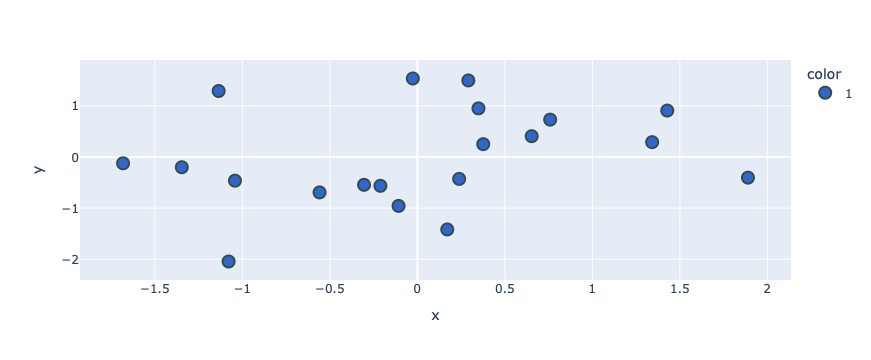

In [12]:
new_df['target'] = new_df['target'].astype('str')
fig = px.scatter(x=new_df['PC1'],
                 y=new_df['PC2'],
                 color=new_df['target'],
                 color_discrete_sequence=px.colors.qualitative.G10
                )

fig.update_traces(marker=dict(size=12,
                              line=dict(width=2,
                                        color='DarkSlateGrey')),
                  selector=dict(mode='markers'))
fig.show()